# Part 9: Conclusion## The Evolution of Epidemic Modelling — and Where Our COVID-19 Model Ended Up---

## Our Journey

We started with a simple question:

> **How can the spread of disease be represented as a dynamical system?**

Through this project, we've explored six increasingly sophisticated models, each arising from the **limitations** of the previous one.

### The Progression

```
SIR
  ↓ (needs latency)
SEIR
  ↓ (needs contact structure)
Network SIR
  ↓ (needs heterogeneity)
Degree-Based SIR
  ↓ (needs individual behavior)
Agent-Based Models
  ↓ (applied to reality)
COVID-19 Models
```

In [1]:
import sys
sys.path.append('../src')

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

print("✓ Setup complete")

✓ Setup complete


## Model Comparison

Let's review what each model contributes.

### 1. SIR Model

**What it does:**
- Partitions population into S, I, R compartments
- Uses ODEs to describe aggregate dynamics
- Introduces R₀ = β/γ as epidemic threshold

**Assumptions:**
- Homogeneous mixing (everyone meets everyone equally)
- Instant infectiousness
- No spatial structure
- No demographic heterogeneity

**Best for:**
- Understanding basic epidemic dynamics
- Quick parameter sensitivity analysis
- Teaching and communication
- Diseases in small, well-mixed populations

**Limitations:**
- Overestimates early growth (no latency)
- Cannot capture network effects
- No spatial spread
- Assumes everyone is identical

### 2. SEIR Model

**What it adds:**
- Exposed (E) compartment for latency period
- Parameter σ (progression rate)
- More realistic timing of epidemic

**Best for:**
- Diseases with significant incubation (COVID-19, measles)
- When timing of interventions matters
- Contact tracing scenarios

**Key insight:**
- Latency **delays** the epidemic peak
- Slightly **reduces** peak magnitude
- More accurate for real diseases

### 3. Network SIR

**What it adds:**
- Explicit contact structure
- Disease spreads along edges
- Different network topologies

**Best for:**
- Social network epidemics
- Targeted interventions (vaccinate hubs)
- Understanding role of network structure

**Key insight:**
- **Structure matters**: scale-free networks → faster spread
- **Hubs are super-spreaders**
- Not everyone is equally connected

### 4. Degree-Based SIR

**What it adds:**
- Degree classes S_k, I_k, R_k
- Heterogeneous contact rates
- Mean-field approximation on networks

**Best for:**
- Bridging mean-field and network models
- Analytical tractability with heterogeneity
- Understanding role of connectivity distribution

**Key insight:**
- Higher-degree individuals drive epidemics
- <k²>/<k> matters for epidemic threshold
- Power-law networks have **no epidemic threshold**

### 5. Agent-Based Models

**What it adds:**
- Individual agents with positions
- Spatial movement
- Contact through proximity
- Stochastic dynamics

**Best for:**
- Spatial epidemics
- Complex individual behaviors
- Policy scenarios (school closures, quarantine)
- When mean-field breaks down

**Key insight:**
- Spatial structure **slows** spread
- Stochasticity matters for small populations
- Can model arbitrarily complex rules

**Limitations:**
- Computationally expensive
- Harder to analyze mathematically
- Requires many parameters

## Final Comparison Table

| Model          | Complexity | Realism   | Computation | When to Use |
|----------------|------------|-----------|-------------|-------------|
| **SIR**        | Low        | Low       | Instant     | Basic understanding, teaching |
| **SEIR**       | Low        | Medium    | Instant     | Diseases with incubation |
| **Network SIR**| Medium     | Medium    | Fast        | Social networks, targeted interventions |
| **Degree-Based**| Medium    | High      | Fast        | Heterogeneous populations, analytical work |
| **ABM**        | High       | Very High | Slow        | Spatial spread, complex behaviors |

### Computational Cost
- SIR/SEIR: milliseconds (solve ODEs)
- Network SIR: seconds (iterate over edges)
- Degree-based: seconds (solve larger ODE system)
- ABM: minutes to hours (many agents, many timesteps)

In [2]:
# Create comprehensive comparison
comparison_data = {
    'Model': ['SIR', 'SEIR', 'Network SIR', 'Degree-Based', 'ABM'],
    'State Variables': ['S, I, R', 'S, E, I, R', 'Node states', 'S_k, I_k, R_k', 'Agent states'],
    'Parameters': ['β, γ', 'β, σ, γ', 'β, γ, network', 'β, γ, P(k)', 'β, γ, speed, radius'],
    'Spatial': ['No', 'No', 'Network', 'Network', 'Yes'],
    'Stochastic': ['No', 'No', 'Yes', 'No', 'Yes'],
    'Code Lines': ['~100', '~120', '~250', '~200', '~350']
}

df = pd.DataFrame(comparison_data)
print("\nModel Comparison Summary:")
print(df.to_string(index=False))


Model Comparison Summary:
       Model State Variables          Parameters Spatial Stochastic Code Lines
         SIR         S, I, R                β, γ      No         No       ~100
        SEIR      S, E, I, R             β, σ, γ      No         No       ~120
 Network SIR     Node states       β, γ, network Network        Yes       ~250
Degree-Based   S_k, I_k, R_k          β, γ, P(k) Network         No       ~200
         ABM    Agent states β, γ, speed, radius     Yes        Yes       ~350


## Answering Key Questions

### Why does SIR work?
- Captures **fundamental dynamics**: transmission and recovery
- **Mean-field approximation** valid for well-mixed populations
- Mathematically tractable
- Good first-order approximation

### Why does SIR fail?
- **Homogeneous mixing** is unrealistic
- **No latency period**
- **No spatial structure**
- **Everyone identical** (no age, behavior differences)

### Why are networks important?
- Real contact patterns are **structured**
- **Hubs** drive spread disproportionately
- Enables **targeted interventions** (vaccinate high-degree nodes)
- Captures **clustering** and **small-world** effects

### Why are ABMs expensive?
- Must track **every individual** (not aggregates)
- Small timesteps for spatial dynamics
- **Many runs** needed (stochastic)
- Computational cost: O(N × T) where N = agents, T = timesteps

### When should each model be used?

**Use SIR when:**
- You need quick insights
- Population is small and well-mixed
- Teaching basic concepts

**Use SEIR when:**
- Latency is important (COVID-19)
- Modeling contact tracing

**Use Network models when:**
- Contact structure is known
- Planning targeted interventions
- Social network epidemics

**Use ABM when:**
- Spatial effects matter
- Complex individual behaviors
- Evaluating detailed policies
- Have computational resources

## Real-World Epidemic Modeling — and Our Version of ItModern epidemic models (like the Imperial College COVID-19 model, Fergusonet al. 2020) **combine multiple layers**: SEIR compartments, age structure,network layers, spatial regions, and policy interventions. The lesson isthat no single layer suffices — the layers must be *fused*.That is exactly what this project's final model does. Notebook 06 walksthrough it step by step for a general reader; here is the engineeringsummary of the stack we built and fitted to real data:| Layer | What it adds | Built in | Data ||---|---|---|---|| Degree-based SEIR | latency + contact heterogeneity (⟨k⟩=6, hubs) | 04 → 08 | — || Metapopulation (56 jurisdictions) | state-to-state coupling | 08 | BTS T-100 air flows || Gravity kernel | who flows where (population ↑, distance ↓) | 08, appendix A | BTS, PPML-calibrated || Time-varying mobility s_i(t) | the pandemic itself changes travel | 08 | BTS monthly || β calibration | transmission from observed growth slopes | 08 | NYT cases || Vaccination (SEIRV) | vaccinated people leave the susceptible pool | 08 | CDC vaccination || Prior infection immunity | ~100M prior infections count as immune | 08 | NYT cumulative || Two-regime β(t) | behaviour/policy cuts transmission after the peak | 08 §8.16, appendix B | observed peak date |The full machine solves ~55,000 coupled ODEs — the SIR of notebook 01,multiplied by degree classes, states, and immunity states.

## What the Fused Model Achieved: the Delta Wave (2021)

The fitted model is compared against the observed US Delta wave
(2021-06-01 → 2021-10-31). The reported curve is scaled by the
window-total ratio π̂ so both are on the same "reported-case" axis:


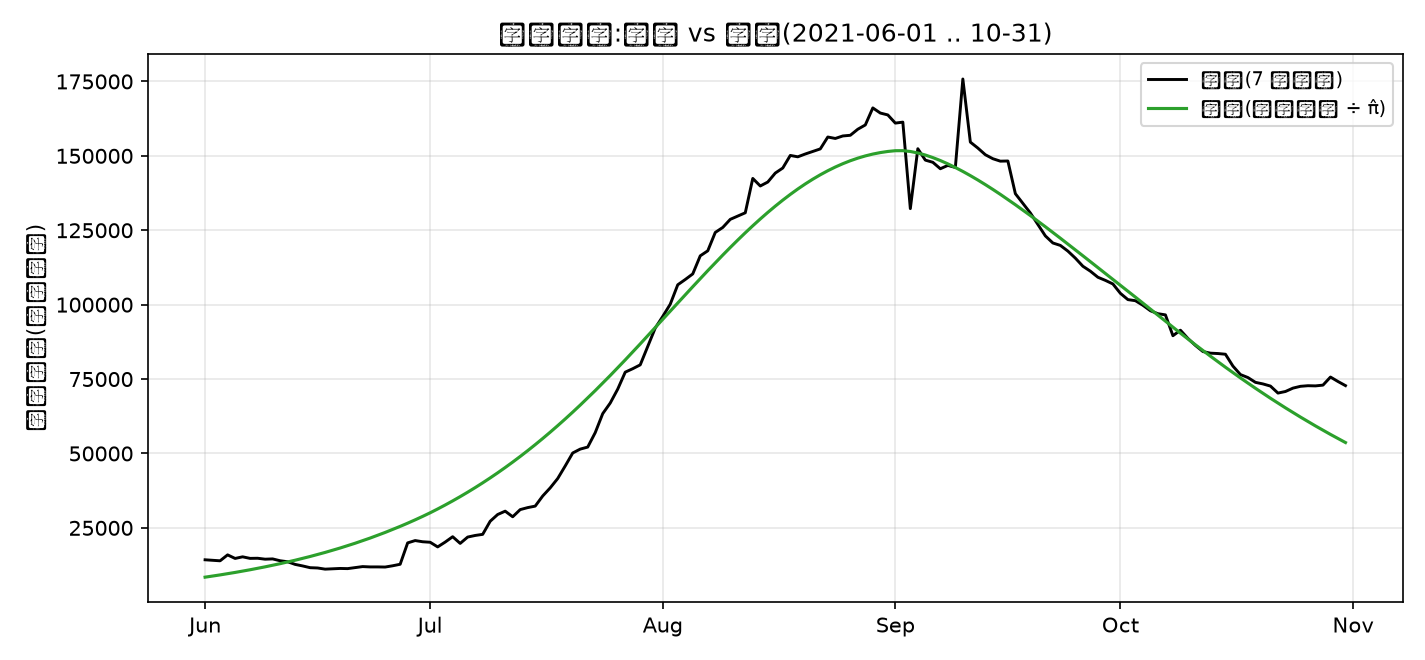

fig86: the final SEIRV + two-regime-beta model vs observed Delta wave


In [3]:
from IPython.display import Image, display
display(Image(filename='../assets/fig86_delta_fit.png'))
print('fig86: the final SEIRV + two-regime-beta model vs observed Delta wave')

**The final scorecard (Delta window):**

| Metric | Value | Meaning |
|---|---|---|
| π̂ (model ÷ observed window totals) | 1.10 | magnitude: essentially exact |
| peak date | model 2021-09-02 vs observed 09-10 | timing: 8 days early |
| October decline (end ÷ peak) | 0.35 vs observed 0.41 | the wave ends the right way |
| R² (log space / linear) | 0.92 / 0.96 | curve shape, 1 = perfect |

Each layer earns its keep: without vaccination and prior immunity the model
explodes (π̂ ≈ 3.4, no peak); without the two-regime β(t) the October
decline is too shallow. And when the same machinery is pointed at the 2022
Omicron wave (appendix B), it quantifies the difference between the two
waves: Delta's decline was mostly *susceptible depletion*, Omicron's
collapse was mostly *behavioural transmission collapse* (ρ = 0.90 vs 0.25).

Appendix A asks a different question — can the gravity kernel alone
*reconstruct* the raw BTS flight matrix? The calibrated kernel lifts the
pooled outbound-share correlation to Pearson 0.45 / Spearman 0.58, with the
honest note that the temporal half of the model is near-perfect (pair
correlation 0.87) while the spatial half is moderate.

**How to explore it yourself**: notebook 06 (layperson walkthrough),
notebook 08 (full model), appendix A (gravity reconstruction), appendix B
(Omicron), `formulae_sheet.md` (all formulas on one page).

## Key Lessons

### 1. All Models Are Wrong, Some Are Useful

- No model captures **all** reality
- Models make **explicit assumptions**
- Value lies in **insights**, not perfect prediction
- Simple models teach intuition

### 2. Model Complexity vs. Understanding

- More complex ≠ always better
- **Start simple**, add complexity as needed
- Each addition should address a **specific limitation**
- Balance realism with tractability

### 3. Assumptions Drive Everything

The history of epidemic modeling is a history of **relaxing assumptions**:
- Homogeneous mixing → networks → spatial ABM
- Instant infectiousness → latency period
- Everyone identical → degree heterogeneity → individual agents

### 4. Computation Enables Realism

- ODEs: analytically tractable, computationally cheap
- Networks: less tractable, still relatively cheap
- ABM: rarely tractable, computationally expensive

Modern computing power enables **realistic ABMs** that weren't possible 30 years ago.

### 5. Models Guide Decisions

Epidemic models inform:
- **Vaccination strategies** (who to vaccinate first?)
- **Intervention timing** (when to lock down?)
- **Resource allocation** (hospital capacity?)
- **Policy evaluation** (which interventions work?)

Models don't make decisions, but they **quantify tradeoffs**.

## Future Directions### What this project already achieved (✓)- [x] **Vaccination models** — SEIRV: vaccinated people leave the susceptible pool (notebook 08 §8.14)- [x] **Prior-infection immunity** — ~100M prior infections as initial immunity (notebook 08 §8.14)- [x] **Metapopulation models** — 56 jurisdictions coupled by real air mobility (notebook 08)- [x] **Time-varying β** — NPI/behaviour drivers, and the two-regime switch (notebook 08 §8.13/§8.16, appendix B)- [x] **Real data fitting** — NYT cases, BTS flights, CDC vaccination, Google CMR, OxCGRT (notebooks 06/08, appendixes)- [x] **Gravity data-reconstruction** — appendix A### Still open (research frontiers)1. **Multi-strain models** (Omicron's immune escape is currently absorbed into fitted parameters, appendix B)2. **Waning immunity** (w > 0) — matters from 2022 onwards3. **Age structure** — age-specific severity and contacts4. **Uncertainty quantification** — parameter posteriors, ensemble forecasts (the CDC forecast-hub standard)5. **Out-of-sample validation** — fitting on one wave, predicting the next6. **GPU acceleration / hybrid ML-mechanistic models**

## Final Takeaway### The Core Message> **The progression of epidemic modelling is fundamentally a progression of assumptions.**Each model exists because a **simpler model failed** to explain an observed phenomenon:- SIR failed to capture latency → **SEIR**- SEIR failed to capture contact structure → **Network models**- Network models needed heterogeneity → **Degree-based models**- Mean-field models missed spatial effects → **ABM**- Single-population models missed geography → **Metapopulation (this project)**- Constant-β models missed immunity and behaviour → **SEIRV + two-regime β(t)**### The Engineering PerspectiveAs engineers and applied mathematicians, we:1. **Start with the simplest model** that could possibly work2. **Identify its limitations** through comparison with data or theory3. **Add complexity** to address specific shortcomings4. **Validate** the new model5. **Repeat**This is how epidemic modelling evolved over the past century — and it isexactly the path this project walked in notebooks 01 → 09.### From Kermack-McKendrick to Our Delta FitThe SIR model from 1927 laid the foundation. The final model of thisproject takes that foundation, adds contact heterogeneity, fuses it into a56-jurisdiction metapopulation driven by real flight data, lets vaccinationand prior immunity shrink the susceptible pool, and lets behaviour reshapetransmission after the peak — and the result **reproduces the 2021 Deltawave: the right size (π̂ = 1.10), the right timing (peak within 8 days),the right ending (October decline), and R² = 0.96**.At their core, all of these models are still built on **S**, **I**, and**R** — but each layer of realism turned a toy into a tool that can look ata real pandemic and say something true about it.---## Thank YouYou've now explored epidemic modeling from first principles to a fitted,data-driven, 55,000-equation model of a real US COVID-19 wave.You understand:- **Why** models exist- **How** they're derived- **When** to use each approach- **What** their limitations are**Most importantly**: you understand that models are **tools for thinking**,not crystal balls — and that the way to make a model say something trueabout the world is to keep asking, layer by layer, *what did the last modelleave out?*Keep exploring, keep questioning assumptions, and keep building better models.---*This project was built to answer one question through computational exploration:**"How can the spread of disease be represented as a dynamical system?"**It was answered with 55,440 coupled equations that fitted a real pandemic wave.**I hope it succeeded.*